# Validación cruzada y regresión lineal
**Hold-out · k-fold · Leave-One-Out · MAE, RMSE y R²**

Vamos a predecir el **consumo de combustible** de autos (millas por galón) a partir de sus características.
Primero ajustamos una regresión lineal simple y una múltiple; después comparamos tres formas de estimar
qué tan bien generaliza el modelo: **hold-out**, **k-fold** y **Leave-One-Out**.

Notebook expositiva: ejecutar en orden con **Shift + Enter** en Google Colab.
Fijamos la versión de scikit-learn para reproducir el ejemplo.
Se necesita conexión a internet para descargar los datos; no hace falta una GPU.

In [1]:
%pip install -q "scikit-learn==1.8.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 11.9 MB/s eta 0:00:00


In [2]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, LeaveOneOut, cross_val_score, cross_validate
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

## 1. Los datos: consumo de autos

Usamos [Auto MPG, de UCI](https://archive.ics.uci.edu/dataset/9/auto+mpg), el mismo dataset de la guía de experimentación:
**398 autos de los años 70 y principios de los 80**. La variable objetivo es `mpg` (millas por galón):
cuanto más alta, menos consume el auto.

Seaborn trae una copia lista para usar. Seis autos no tienen potencia (`horsepower`) registrada; los descartamos.

In [3]:
autos = sns.load_dataset("mpg").dropna()
print("Autos:", len(autos))
display(autos.head())

Autos: 392


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


`origin` es categórica (usa, europe, japan). La convertimos en **variables dummy**: una columna 0/1 por origen,
dejando uno como referencia (`drop_first=True`). El nombre del modelo no lo usamos.

In [4]:
datos = pd.get_dummies(autos.drop(columns="name"), columns=["origin"], drop_first=True, dtype=int)
X = datos.drop(columns="mpg")
y = datos["mpg"]
X.head()

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_japan,origin_usa
0,8,307.0,130.0,3504,12.0,70,0,1
1,8,350.0,165.0,3693,11.5,70,0,1
2,8,318.0,150.0,3436,11.0,70,0,1
3,8,304.0,150.0,3433,12.0,70,0,1
4,8,302.0,140.0,3449,10.5,70,0,1


## 2. Regresión lineal simple: consumo según el peso

Empezamos con **una sola variable**: el peso del auto (en libras). La recta tiene la forma
**mpg = β₀ + β₁ · peso**. `fit` encuentra los coeficientes por mínimos cuadrados.

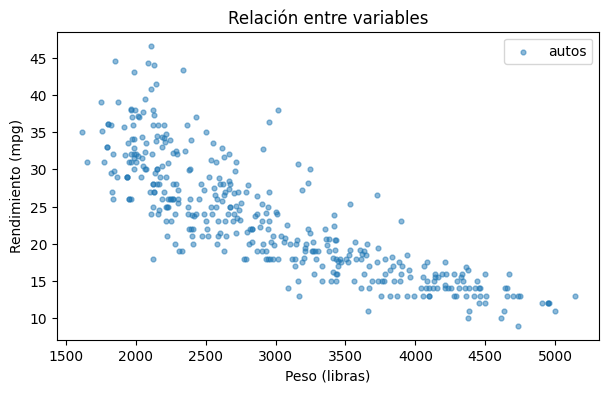

In [14]:
orden = X["weight"].sort_values()
plt.figure(figsize=(7, 4))
plt.scatter(X["weight"], y, s=12, alpha=0.5, label="autos")
plt.xlabel("Peso (libras)"); plt.ylabel("Rendimiento (mpg)"); plt.legend()
plt.title("Relación entre variables")
plt.show()

In [19]:
x_indep = X[["weight"]]

simple = LinearRegression()
simple.fit(x_indep, y)

b0, b1 = simple.intercept_, simple.coef_[0]
print(f"mpg = {b0:.2f} + ({b1:.5f}) · peso")
print(f"Cada 1.000 libras adicionales, el rendimiento baja {-b1 * 1000:.1f} mpg")

mpg = 46.22 + (-0.00765) · peso
Cada 1.000 libras adicionales, el rendimiento baja 7.6 mpg


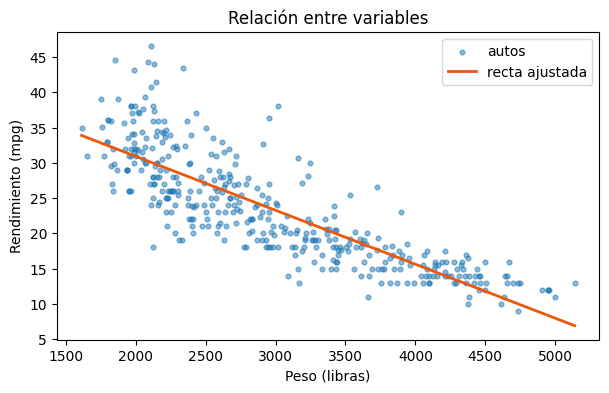

In [15]:
orden = X["weight"].sort_values()
plt.figure(figsize=(7, 4))
plt.scatter(X["weight"], y, s=12, alpha=0.5, label="autos")
plt.plot(orden, simple.predict(orden.to_frame()), color="#EA580C", linewidth=2, label="recta ajustada")
plt.xlabel("Peso (libras)"); plt.ylabel("Rendimiento (mpg)"); plt.legend()
plt.title("Relación entre variables")
plt.show()


**Lectura:** la pendiente es negativa: los autos más pesados recorren menos millas por galón.
La nube de puntos se curva un poco, así que una recta no captura toda la relación. Lo retomamos en la clase de regresiones no lineales.

## 3. Regresión lineal múltiple con hold-out

Ahora usamos **todos los atributos**. Reservamos **20 % para prueba** (`random_state=42`) y entrenamos con el resto,
como hicimos en clasificación. Esta partición única es el método **hold-out**.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Entrenamiento:", len(X_train), "· Prueba:", len(X_test))

multiple = LinearRegression()
multiple.fit(X_train, y_train)
pd.DataFrame({"Coeficiente": multiple.coef_}, index=X.columns).round(4)

Entrenamiento: 313 · Prueba: 79


,Coeficiente
cylinders,-0.3421
displacement,0.0192
horsepower,-0.0216
weight,-0.0064
acceleration,0.0422
model_year,0.7972
origin_japan,0.3305
origin_usa,-2.8755


Cada coeficiente indica cuánto cambia `mpg` cuando esa variable aumenta en una unidad **y las demás quedan fijas**.
Ojo: las variables están en escalas distintas (libras, años, cilindros), así que el tamaño del coeficiente
**no** indica directamente cuál es más importante.

## 4. Métricas de regresión

Calculamos las tres métricas de la clase sobre entrenamiento y sobre prueba:
- **MAE**: error absoluto promedio, en mpg.
- **RMSE**: raíz del error cuadrático medio, en mpg; pesa más los errores grandes.
- **R²**: proporción de la variabilidad de `mpg` que explica el modelo.

In [7]:
def metricas(y_real, y_pred):
    return {"MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": root_mean_squared_error(y_real, y_pred),
            "R²": r2_score(y_real, y_pred)}

pd.DataFrame({"Entrenamiento": metricas(y_train, multiple.predict(X_train)),
              "Prueba": metricas(y_test, multiple.predict(X_test))}).round(3)

,Entrenamiento,Prueba
MAE,2.545,2.462
RMSE,3.288,3.256
R²,0.829,0.792


## 5. El problema del hold-out: depende de la partición

Dentro del **entrenamiento**, separamos 20 % como validación y repetimos con **diez semillas distintas**.
El modelo y los datos son los mismos; solo cambia qué autos caen en validación. La prueba sigue reservada.

In [8]:
filas = []
for semilla in range(10):
    Xa, Xb, ya, yb = train_test_split(X_train, y_train, test_size=0.20, random_state=semilla)
    modelo = LinearRegression().fit(Xa, ya)
    filas.append({"Semilla": semilla, **metricas(yb, modelo.predict(Xb))})
holdout = pd.DataFrame(filas)
display(holdout.round(3))
print(f"R² de validación: entre {holdout['R²'].min():.3f} y {holdout['R²'].max():.3f}")

,Semilla,MAE,RMSE,R²
0,0,2.637,3.253,0.804
1,1,2.538,3.343,0.835
2,2,2.823,3.350,0.819
3,3,2.657,3.439,0.804
4,4,2.840,3.540,0.782
5,5,2.611,3.453,0.809
6,6,2.643,3.189,0.842
7,7,2.407,3.211,0.830
8,8,2.630,3.542,0.807
9,9,2.566,3.164,0.816


R² de validación: entre 0.782 y 0.842


**Lectura:** con una sola partición, el resultado que informamos depende de la suerte.
La validación cruzada reduce esa dependencia porque **todas** las observaciones validan una vez.

## 6. Validación cruzada k-fold

`KFold(n_splits=5)` divide el **entrenamiento** en cinco partes. En cada vuelta entrena con cuatro y valida con la restante.
`shuffle=True` mezcla las filas antes de dividir; `random_state` hace reproducible la mezcla.

`cross_validate` permite pedir varias métricas a la vez. scikit-learn siempre **maximiza** los scores,
por eso los errores vienen con signo negativo (`neg_...`): los invertimos para leerlos.

In [9]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
res = cross_validate(LinearRegression(), X_train, y_train, cv=kf,
                     scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
folds = pd.DataFrame({"Vuelta": range(1, 6),
                      "MAE": -res["test_neg_mean_absolute_error"],
                      "RMSE": -res["test_neg_root_mean_squared_error"],
                      "R²": res["test_r2"]})
display(folds.round(3))
print("Promedio ± desvío")
print(folds[["MAE", "RMSE", "R²"]].agg(["mean", "std"]).round(3))

,Vuelta,MAE,RMSE,R²
0,1,2.252,2.917,0.815
1,2,2.443,3.135,0.840
2,3,2.738,3.223,0.817
3,4,2.708,3.423,0.825
4,5,2.946,4.137,0.796


Promedio ± desvío
        MAE   RMSE     R²
mean  2.617  3.367  0.819
std   0.271  0.467  0.016


Informamos el **promedio y el desvío** de las cinco vueltas. El desvío muestra cuánto varía el resultado
según qué datos se usan para validar.

## 7. Leave-One-Out

Con `LeaveOneOut` hay **una vuelta por observación**: cada auto valida solo una vez.
Como cada validación tiene un único dato, no se puede calcular R² por vuelta; promediamos los errores.
Medimos también el tiempo: el costo crece con la cantidad de observaciones.

In [10]:
loo = LeaveOneOut()
print("Vueltas:", loo.get_n_splits(X_train))

inicio = time.perf_counter()
errores_abs = -cross_val_score(LinearRegression(), X_train, y_train, cv=loo, scoring="neg_mean_absolute_error")
errores_cuad = -cross_val_score(LinearRegression(), X_train, y_train, cv=loo, scoring="neg_mean_squared_error")
duracion = time.perf_counter() - inicio

print(f"MAE (LOO):  {errores_abs.mean():.3f}")
print(f"RMSE (LOO): {np.sqrt(errores_cuad.mean()):.3f}")
print(f"Tiempo: {duracion:.1f} s para {2 * len(X_train)} entrenamientos")

Vueltas: 313
MAE (LOO):  2.629
RMSE (LOO): 3.404
Tiempo: 10.5 s para 626 entrenamientos


## 8. Comparar las tres estimaciones

Juntamos el MAE estimado por cada método. Ninguno usó el conjunto de prueba del punto 3.

In [11]:
pd.DataFrame({
    "Método": ["Hold-out (10 semillas)", "k-fold (k = 5)", "Leave-One-Out"],
    "Entrenamientos": [10, 5, len(X_train)],
    "MAE estimado": [holdout["MAE"].mean(), folds["MAE"].mean(), errores_abs.mean()],
    "Desvío del MAE": [holdout["MAE"].std(), folds["MAE"].std(), np.nan]
}).round(3)

,Método,Entrenamientos,MAE estimado,Desvío del MAE
0,Hold-out (10 semillas),10,2.635,0.127
1,k-fold (k = 5),5,2.617,0.271
2,Leave-One-Out,313,2.629,NaN


**Lectura:** las tres estimaciones quedan cerca, pero no cuestan lo mismo. k-fold da una buena estimación
con pocos entrenamientos; LOO entrena un modelo por auto. Con datasets grandes, LOO deja de ser práctico.

## 9. Mirar los residuos

Antes de quedarnos con el modelo, revisamos los **residuos** (real − predicho) en prueba.
Si el modelo lineal fuera adecuado, deberían repartirse sin forma alrededor de cero.

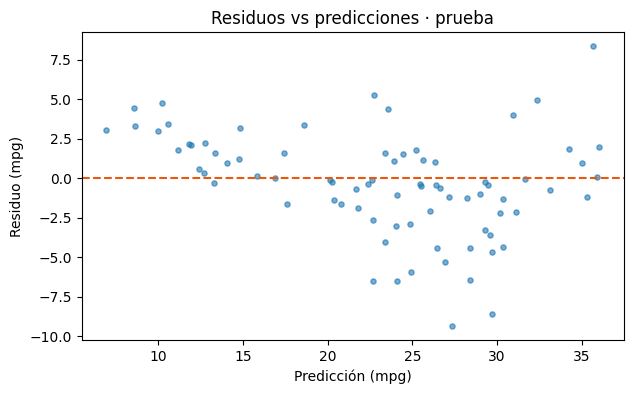

In [12]:
pred = multiple.predict(X_test)
residuos = y_test - pred
plt.figure(figsize=(7, 4))
plt.scatter(pred, residuos, s=14, alpha=0.6)
plt.axhline(0, color="#EA580C", linestyle="--")
plt.xlabel("Predicción (mpg)"); plt.ylabel("Residuo (mpg)")
plt.title("Residuos vs predicciones · prueba")
plt.show()

**Lectura:** los residuos forman una leve curva y se abren hacia predicciones altas. Es la misma no linealidad
que vimos con el peso: el modelo lineal es un buen punto de partida, pero no captura todo.

**La idea central:** usamos validación cruzada para **estimar** el desempeño sin tocar la prueba,
y reportamos una métrica en unidades de la variable (MAE o RMSE) junto con el R².

## Para practicar

1. Repitan el punto 6 con `n_splits=10`. ¿Cambia el promedio? ¿Y el desvío?
2. Entrenen un modelo solo con `weight`, `model_year` y `origin`. Compárenlo con el modelo completo usando k-fold. ¿Vale la pena usar todas las variables?
3. Continúen con la **guía de experimentación**, sección *Algoritmos de Regresión*, consigna de Auto MPG.

**Fuentes:** [Auto MPG, UCI (1993), CC BY 4.0](https://doi.org/10.24432/C5859H)
· [Cross-validation, scikit-learn](https://scikit-learn.org/stable/modules/cross_validation.html)
· [Regression metrics, scikit-learn](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)